# Experiment 11: Project LAST EXIT – Intelligent Disaster Evacuation System

**Aim:** To develop an intelligent system that coordinates rescue teams and helps people evacuate safely during a disaster.


## Imports & Setup

In [7]:
import random
import heapq
import copy
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from collections import defaultdict

random.seed(42)
np.random.seed(42)
print("Libraries loaded successfully.")


Libraries loaded successfully.


---
## Exercise 1: Knowledge Representation

Represent rescue teams, affected areas, shelters, and their relationships using frames/semantic-network style dictionaries.


In [8]:
# ── Rescue Teams ──────────────────────────────────────────────────────────────
rescue_teams = {
    "RT1": {"name": "Alpha Squad",  "capacity": 30, "equipment": ["boat", "medkit"], "location": "Base",   "available": True},
    "RT2": {"name": "Bravo Squad",  "capacity": 25, "equipment": ["helicopter"],      "location": "Base",   "available": True},
    "RT3": {"name": "Charlie Squad","capacity": 20, "equipment": ["truck", "medkit"], "location": "Base",   "available": True},
    "RT4": {"name": "Delta Squad",  "capacity": 15, "equipment": ["boat"],            "location": "Base",   "available": True},
}

# ── Affected Areas ────────────────────────────────────────────────────────────
affected_areas = {
    "A1": {"name": "North District", "population": 120, "flood_level": 0.85, "road_condition": 0.3, "priority": None},
    "A2": {"name": "East Sector",    "population":  80, "flood_level": 0.60, "road_condition": 0.6, "priority": None},
    "A3": {"name": "South Zone",     "population":  50, "flood_level": 0.40, "road_condition": 0.8, "priority": None},
    "A4": {"name": "West Block",     "population":  95, "flood_level": 0.75, "road_condition": 0.2, "priority": None},
    "A5": {"name": "Central Plaza",  "population":  30, "flood_level": 0.20, "road_condition": 0.9, "priority": None},
}

# ── Shelters ──────────────────────────────────────────────────────────────────
shelters = {
    "S1": {"name": "Community Hall",   "capacity": 150, "current_occupancy": 20,  "available": True,  "supplies": ["food","water","medical"]},
    "S2": {"name": "High School",      "capacity": 200, "current_occupancy": 50,  "available": True,  "supplies": ["food","water"]},
    "S3": {"name": "Sports Complex",   "capacity": 100, "current_occupancy": 80,  "available": True,  "supplies": ["water"]},
    "S4": {"name": "Government Office","capacity":  80, "current_occupancy": 10,  "available": True,  "supplies": ["food","water","medical"]},
}

# ── Road Network (area → area or shelter, weight = travel_time in minutes) ────
road_network = {
    "Base": {"A1": 20, "A2": 15, "A3": 25, "A4": 18, "A5": 10},
    "A1":   {"Base": 20, "A2": 10, "A4": 12, "S1": 8},
    "A2":   {"Base": 15, "A1": 10, "A3": 14, "S2": 6},
    "A3":   {"Base": 25, "A2": 14, "A5": 8,  "S3": 5},
    "A4":   {"Base": 18, "A1": 12, "S1": 15, "S4": 20},
    "A5":   {"Base": 10, "A3": 8,  "S2": 12, "S4": 10},
    "S1":   {"A1": 8,  "A4": 15},
    "S2":   {"A2": 6,  "A5": 12},
    "S3":   {"A3": 5},
    "S4":   {"A4": 20, "A5": 10},
}

print("Knowledge Base constructed:")
print(f"  Rescue Teams  : {list(rescue_teams.keys())}")
print(f"  Affected Areas: {list(affected_areas.keys())}")
print(f"  Shelters      : {list(shelters.keys())}")
print(f"  Road nodes    : {list(road_network.keys())}")


Knowledge Base constructed:
  Rescue Teams  : ['RT1', 'RT2', 'RT3', 'RT4']
  Affected Areas: ['A1', 'A2', 'A3', 'A4', 'A5']
  Shelters      : ['S1', 'S2', 'S3', 'S4']
  Road nodes    : ['Base', 'A1', 'A2', 'A3', 'A4', 'A5', 'S1', 'S2', 'S3', 'S4']


---
## Exercise 2: Rule-Based Reasoning

Forward-chaining IF–THEN rules to determine evacuation priority and recommend actions for each affected area.


In [9]:
def classify_priority(flood_level, road_condition, population):
    """
    Forward-chaining rules to classify evacuation priority.
    Returns (priority_label, recommended_action)
    """
    # Rule 1 – CRITICAL
    if flood_level > 0.7 and road_condition < 0.4:
        return "CRITICAL", "Deploy helicopter or boat immediately"
    # Rule 2 – HIGH
    if flood_level > 0.7 or (flood_level > 0.5 and road_condition < 0.5):
        return "HIGH", "Send boat/truck rescue team with medical kit"
    # Rule 3 – MEDIUM
    if flood_level > 0.3 and road_condition >= 0.5:
        return "MEDIUM", "Send ground rescue team via truck"
    # Rule 4 – LOW
    return "LOW", "Monitor situation; prepare evacuation routes"

print(f"{'Area':<6} {'Flood':>6} {'Road':>6} {'Pop':>5}  Priority   Action")
print("-" * 80)
for aid, area in affected_areas.items():
    p, action = classify_priority(area["flood_level"], area["road_condition"], area["population"])
    area["priority"] = p
    area["action"]   = action
    print(f"{aid:<6} {area['flood_level']:>6.2f} {area['road_condition']:>6.2f} {area['population']:>5}  {p:<10} {action}")


Area    Flood   Road   Pop  Priority   Action
--------------------------------------------------------------------------------
A1       0.85   0.30   120  CRITICAL   Deploy helicopter or boat immediately
A2       0.60   0.60    80  MEDIUM     Send ground rescue team via truck
A3       0.40   0.80    50  MEDIUM     Send ground rescue team via truck
A4       0.75   0.20    95  CRITICAL   Deploy helicopter or boat immediately
A5       0.20   0.90    30  LOW        Monitor situation; prepare evacuation routes


---
## Exercise 3: Handling Uncertainty – Fuzzy Logic

Fuzzy membership functions for flood level, road condition, and population density produce a defuzzified **urgency score** (0–10) for each area.


In [10]:
# ── Fuzzy membership functions ────────────────────────────────────────────────
def mf_low(x, a, b):
    """Decreasing linear membership (high → low)."""
    if x <= a: return 1.0
    if x >= b: return 0.0
    return (b - x) / (b - a)

def mf_high(x, a, b):
    """Increasing linear membership (low → high)."""
    if x <= a: return 0.0
    if x >= b: return 1.0
    return (x - a) / (b - a)

def mf_medium(x, a, b, c):
    """Triangular membership."""
    if x <= a or x >= c: return 0.0
    if x <= b: return (x - a) / (b - a)
    return (c - x) / (c - b)

def fuzzy_urgency(flood, road, pop_norm):
    """
    Compute a crisp urgency score 0–10 via fuzzy inference.
    pop_norm: population normalised to [0,1] (0=30 people, 1=120 people).
    """
    # Flood level memberships
    fl_low  = mf_low(flood,  0.0, 0.4)
    fl_med  = mf_medium(flood, 0.3, 0.6, 0.8)
    fl_high = mf_high(flood, 0.6, 1.0)

    # Road condition memberships (bad road = low value)
    rd_bad  = mf_low(road,  0.0, 0.5)
    rd_good = mf_high(road, 0.4, 1.0)

    # Population memberships
    pop_low  = mf_low(pop_norm,  0.0, 0.4)
    pop_high = mf_high(pop_norm, 0.5, 1.0)

    # Fuzzy rules → (weight, urgency_centre)
    rules = [
        (min(fl_high, rd_bad,  pop_high), 9.5),   # CRITICAL
        (min(fl_high, rd_bad,  pop_low),  8.0),    # HIGH-A
        (min(fl_high, rd_good, pop_high), 7.5),    # HIGH-B
        (min(fl_med,  rd_bad,  pop_high), 7.0),    # HIGH-C
        (min(fl_high, rd_good, pop_low),  6.0),    # MEDIUM-A
        (min(fl_med,  rd_good, pop_high), 5.5),    # MEDIUM-B
        (min(fl_med,  rd_bad,  pop_low),  5.0),    # MEDIUM-C
        (min(fl_med,  rd_good, pop_low),  4.0),    # LOW-A
        (min(fl_low,  rd_bad,  pop_high), 3.5),    # LOW-B
        (min(fl_low,  rd_good, pop_low),  1.5),    # VERY-LOW
    ]

    numerator   = sum(w * c for w, c in rules)
    denominator = sum(w      for w, _ in rules)
    return round(numerator / denominator, 3) if denominator > 0 else 0.0

# Normalise population
pops   = [a["population"] for a in affected_areas.values()]
pop_min, pop_max = min(pops), max(pops)

print(f"{'Area':<6} {'Flood':>6} {'Road':>6} {'Pop':>5}  Urgency Score")
print("-" * 50)
for aid, area in affected_areas.items():
    pop_norm = (area["population"] - pop_min) / (pop_max - pop_min)
    score    = fuzzy_urgency(area["flood_level"], area["road_condition"], pop_norm)
    area["urgency_score"] = score
    print(f"{aid:<6} {area['flood_level']:>6.2f} {area['road_condition']:>6.2f} {area['population']:>5}  {score:>5.3f}")


Area    Flood   Road   Pop  Urgency Score
--------------------------------------------------
A1       0.85   0.30   120  9.500
A2       0.60   0.60    80  5.500
A3       0.40   0.80    50  4.000
A4       0.75   0.20    95  8.500
A5       0.20   0.90    30  1.500


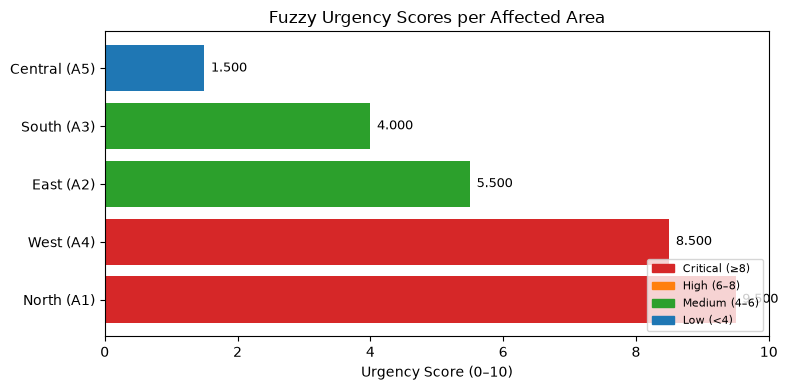

In [11]:
# Visualise fuzzy urgency scores
fig, ax = plt.subplots(figsize=(8, 4))
areas_sorted = sorted(affected_areas.items(), key=lambda x: -x[1]["urgency_score"])
labels = [a["name"].split()[0] + " (" + k + ")" for k, a in areas_sorted]
scores = [a["urgency_score"] for _, a in areas_sorted]
colors = ["#d62728" if s >= 8 else "#ff7f0e" if s >= 6 else "#2ca02c" if s >= 4 else "#1f77b4" for s in scores]
bars   = ax.barh(labels, scores, color=colors)
ax.set_xlabel("Urgency Score (0–10)")
ax.set_title("Fuzzy Urgency Scores per Affected Area")
ax.set_xlim(0, 10)
for bar, score in zip(bars, scores):
    ax.text(score + 0.1, bar.get_y() + bar.get_height()/2, f"{score:.3f}", va="center", fontsize=9)
patches = [mpatches.Patch(color="#d62728", label="Critical (≥8)"),
           mpatches.Patch(color="#ff7f0e", label="High (6–8)"),
           mpatches.Patch(color="#2ca02c", label="Medium (4–6)"),
           mpatches.Patch(color="#1f77b4", label="Low (<4)")]
ax.legend(handles=patches, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


---
## Exercise 4: Resource Allocation

Assign rescue teams to areas (highest urgency first) and find the best available shelter using a greedy approach with Dijkstra shortest-path routing.


In [12]:
def dijkstra(graph, source):
    """Return dict of shortest distances from source to all reachable nodes."""
    dist = {source: 0}
    pq   = [(0, source)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist.get(u, float("inf")): continue
        for v, w in graph.get(u, {}).items():
            nd = d + w
            if nd < dist.get(v, float("inf")):
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return dist

def find_best_shelter(area_id, shelters, road_network):
    """Return (shelter_id, travel_time) with max remaining capacity reachable."""
    dists = dijkstra(road_network, area_id)
    candidates = []
    for sid, s in shelters.items():
        if s["available"] and (s["capacity"] - s["current_occupancy"]) > 0:
            t = dists.get(sid, float("inf"))
            remaining = s["capacity"] - s["current_occupancy"]
            candidates.append((t, -remaining, sid))
    candidates.sort()
    if not candidates:
        return None, float("inf")
    return candidates[0][2], candidates[0][0]

# Sort areas by urgency (descending)
sorted_areas = sorted(affected_areas.items(), key=lambda x: -x[1]["urgency_score"])
available_teams = list(rescue_teams.keys())
allocation = {}

print(f"{'Area':<6} {'Priority':<10} {'Team':<8} {'Shelter':<12} {'Travel (min)':>12}")
print("-" * 60)
for aid, area in sorted_areas:
    team = available_teams.pop(0) if available_teams else "NONE"
    sid, travel = find_best_shelter(aid, shelters, road_network)
    if sid:
        needed = area["population"]
        shelters[sid]["current_occupancy"] += min(needed, shelters[sid]["capacity"] - shelters[sid]["current_occupancy"])
    allocation[aid] = {"team": team, "shelter": sid, "travel_time": travel}
    print(f"{aid:<6} {area['priority']:<10} {team:<8} {str(sid):<12} {travel:>12.1f}")

print("Shelter Occupancy After Allocation:")
for sid, s in shelters.items():
    pct = s["current_occupancy"] / s["capacity"] * 100
    print(f"  {sid} ({s['name']}): {s['current_occupancy']}/{s['capacity']} ({pct:.1f}%)")


Area   Priority   Team     Shelter      Travel (min)
------------------------------------------------------------
A1     CRITICAL   RT1      S1                    8.0
A4     CRITICAL   RT2      S1                   15.0
A2     MEDIUM     RT3      S2                    6.0
A3     MEDIUM     RT4      S3                    5.0
A5     LOW        NONE     S4                   10.0
Shelter Occupancy After Allocation:
  S1 (Community Hall): 150/150 (100.0%)
  S2 (High School): 130/200 (65.0%)
  S3 (Sports Complex): 100/100 (100.0%)
  S4 (Government Office): 40/80 (50.0%)


---
## Exercise 5: Multi-Agent Coordination – Contract Net Protocol (CNP)

The **Manager** broadcasts task announcements; rescue team agents bid based on capacity and equipment match; the manager awards contracts to the best bidder and resolves conflicts.


In [14]:
class RescueTeamAgent:
    def __init__(self, tid, info):
        self.id   = tid
        self.info = copy.deepcopy(info)
        self.tasks = []

    def bid(self, task):
        """Return a bid score (higher = better fit). None if cannot fulfil."""
        if not self.info["available"]: return None
        required_equip = task.get("required_equipment", [])
        has_equip      = all(e in self.info["equipment"] for e in required_equip)
        if not has_equip:            return None
        pop_fit  = min(self.info["capacity"] / max(task["population"], 1), 1.0)
        equip_bonus = 0.2 * len(required_equip)
        return round(pop_fit + equip_bonus, 3)

    def accept_task(self, task):
        self.tasks.append(task)
        self.info["available"] = False

class ManagerAgent:
    def __init__(self, teams):
        self.agents = [RescueTeamAgent(tid, info) for tid, info in teams.items()]

    def announce(self, task):
        bids = []
        for agent in self.agents:
            score = agent.bid(task)
            if score is not None:
                bids.append((score, agent))
        return sorted(bids, reverse=True)

    def award(self, task):
        bids = self.announce(task)
        if not bids:
            print(f"  [CNP] Task '{task['area']}': NO BIDDER – conflict/unavailable")
            return None
        winner_score, winner = bids[0]
        winner.accept_task(task)
        print(f"  [CNP] Task '{task['area']}': awarded to {winner.id} "
              f"({winner.info['name']}) | bid={winner_score}")
        return winner.id

# Define tasks derived from area priorities
tasks = []
for aid, area in sorted(affected_areas.items(), key=lambda x: -x[1]["urgency_score"]):
    req_eq = []
    if area["flood_level"] > 0.7 and area["road_condition"] < 0.4:
        req_eq = ["boat"]
    elif area["flood_level"] > 0.7:
        req_eq = ["helicopter"]
    elif area.get("priority") == "MEDIUM":
        req_eq = ["truck"]
    tasks.append({"area": aid, "population": area["population"],
                  "urgency": area["urgency_score"], "required_equipment": req_eq})

manager = ManagerAgent(rescue_teams)
print("Contract Net Protocol – Task Allocation:")
print("-" * 60)
cnp_result = {}
for task in tasks:
    winner_id = manager.award(task)
    cnp_result[task["area"]] = winner_id

print("Final CNP Agent Assignments:")
for agent in manager.agents:
    assigned = [t["area"] for t in agent.tasks]
    print(f"  {agent.id} ({agent.info['name']}): {assigned if assigned else 'idle'}")


Contract Net Protocol – Task Allocation:
------------------------------------------------------------
  [CNP] Task 'A1': awarded to RT1 (Alpha Squad) | bid=0.45
  [CNP] Task 'A4': awarded to RT4 (Delta Squad) | bid=0.358
  [CNP] Task 'A2': awarded to RT3 (Charlie Squad) | bid=0.45
  [CNP] Task 'A3': NO BIDDER – conflict/unavailable
  [CNP] Task 'A5': awarded to RT2 (Bravo Squad) | bid=0.833
Final CNP Agent Assignments:
  RT1 (Alpha Squad): ['A1']
  RT2 (Bravo Squad): ['A5']
  RT3 (Charlie Squad): ['A2']
  RT4 (Delta Squad): ['A4']


---
## Exercise 6: Simulation and Evaluation

Simulate two scenarios:
1. **Normal** – baseline evacuation.
2. **Crisis** – blocked route (A1→S1) + shelter S3 unavailable.

Compare evacuation time, resource usage, and people evacuated safely.


In [15]:
def simulate_evacuation(scenario_name, road_net, shelters_state, teams_state,
                        areas_state, blocked_edges=None, unavailable_shelters=None):
    """
    Simulate evacuation. Returns metrics dict.
    blocked_edges:        list of (u, v) edges to remove from road_net
    unavailable_shelters: list of shelter IDs to mark unavailable
    """
    # Deep-copy mutable state
    rn  = copy.deepcopy(road_net)
    sh  = copy.deepcopy(shelters_state)
    ts  = copy.deepcopy(teams_state)
    ar  = copy.deepcopy(areas_state)

    # Apply perturbations
    if blocked_edges:
        for u, v in blocked_edges:
            rn.get(u, {}).pop(v, None)
            rn.get(v, {}).pop(u, None)
    if unavailable_shelters:
        for sid in unavailable_shelters:
            if sid in sh: sh[sid]["available"] = False

    sorted_ar = sorted(ar.items(), key=lambda x: -x[1]["urgency_score"])
    avail_teams = list(ts.keys())

    total_time   = 0
    total_people = 0
    teams_used   = 0
    evacuations  = []

    for aid, area in sorted_ar:
        if not avail_teams:
            evacuations.append({"area": aid, "status": "WAITING – no team",
                                "people": 0, "time": 0, "shelter": None})
            continue
        team = avail_teams.pop(0)
        teams_used += 1

        # Travel from Base to area
        base_dists = dijkstra(rn, "Base")
        travel_to  = base_dists.get(aid, float("inf"))

        # Find shelter
        sid, travel_from = find_best_shelter(aid, sh, rn)

        if sid is None:
            evacuations.append({"area": aid, "status": "NO SHELTER",
                                "people": 0, "time": travel_to, "shelter": None})
            avail_teams.append(team)   # return team
            continue

        evac_time = travel_to + travel_from
        cap_remaining = sh[sid]["capacity"] - sh[sid]["current_occupancy"]
        people_saved  = min(area["population"], ts[team]["capacity"], cap_remaining)
        sh[sid]["current_occupancy"] += people_saved
        total_time   += evac_time
        total_people += people_saved

        evacuations.append({"area": aid, "team": team, "shelter": sid,
                            "people": people_saved, "time": evac_time,
                            "status": "EVACUATED"})

    metrics = {
        "scenario":       scenario_name,
        "total_time_min": round(total_time, 1),
        "avg_time_min":   round(total_time / max(len(sorted_ar), 1), 1),
        "people_saved":   total_people,
        "teams_used":     teams_used,
        "detail":         evacuations,
    }
    return metrics

# ── Run scenarios ─────────────────────────────────────────────────────────────
# Reset shelter occupancy for fair comparison
shelters_reset = {k: dict(v, current_occupancy=v["current_occupancy"] - (v["current_occupancy"] - [20,50,80,10][i]))
                  for i, (k, v) in enumerate(shelters.items())}
# Restore original occupancy
original_occ = {"S1": 20, "S2": 50, "S3": 80, "S4": 10}
for sid in shelters:
    shelters[sid]["current_occupancy"] = original_occ[sid]
    shelters[sid]["available"] = True

scenario_normal = simulate_evacuation(
    "Normal", road_network, shelters, rescue_teams, affected_areas
)
scenario_crisis = simulate_evacuation(
    "Crisis (Blocked A1→S1, S3 unavailable)", road_network, shelters, rescue_teams, affected_areas,
    blocked_edges=[("A1","S1"), ("A4","S1")],
    unavailable_shelters=["S3"]
)

for sc in [scenario_normal, scenario_crisis]:
    print(f"\n=== Scenario: {sc['scenario']} ===")
    print(f"  People Evacuated : {sc['people_saved']}")
    print(f"  Total Time (min) : {sc['total_time_min']}")
    print(f"  Avg  Time (min)  : {sc['avg_time_min']}")
    print(f"  Teams Used       : {sc['teams_used']}")
    print(f"  {'Area':<6} {'Team':<8} {'Shelter':<8} {'People':>8} {'Time':>8}  Status")
    for d in sc["detail"]:
        print(f"  {d['area']:<6} {str(d.get('team','–')):<8} {str(d.get('shelter','–')):<8} "
              f"{d['people']:>8} {d['time']:>8.1f}  {d['status']}")



=== Scenario: Normal ===
  People Evacuated : 90
  Total Time (min) : 105
  Avg  Time (min)  : 21.0
  Teams Used       : 4
  Area   Team     Shelter    People     Time  Status
  A1     RT1      S1             30     28.0  EVACUATED
  A4     RT2      S1             25     33.0  EVACUATED
  A2     RT3      S2             20     21.0  EVACUATED
  A3     RT4      S3             15     23.0  EVACUATED
  A5     –        None            0      0.0  WAITING – no team

=== Scenario: Crisis (Blocked A1→S1, S3 unavailable) ===
  People Evacuated : 90
  Total Time (min) : 131
  Avg  Time (min)  : 26.2
  Teams Used       : 4
  Area   Team     Shelter    People     Time  Status
  A1     RT1      S2             30     36.0  EVACUATED
  A4     RT2      S4             25     38.0  EVACUATED
  A2     RT3      S2             20     21.0  EVACUATED
  A3     RT4      S4             15     36.0  EVACUATED
  A5     –        None            0      0.0  WAITING – no team


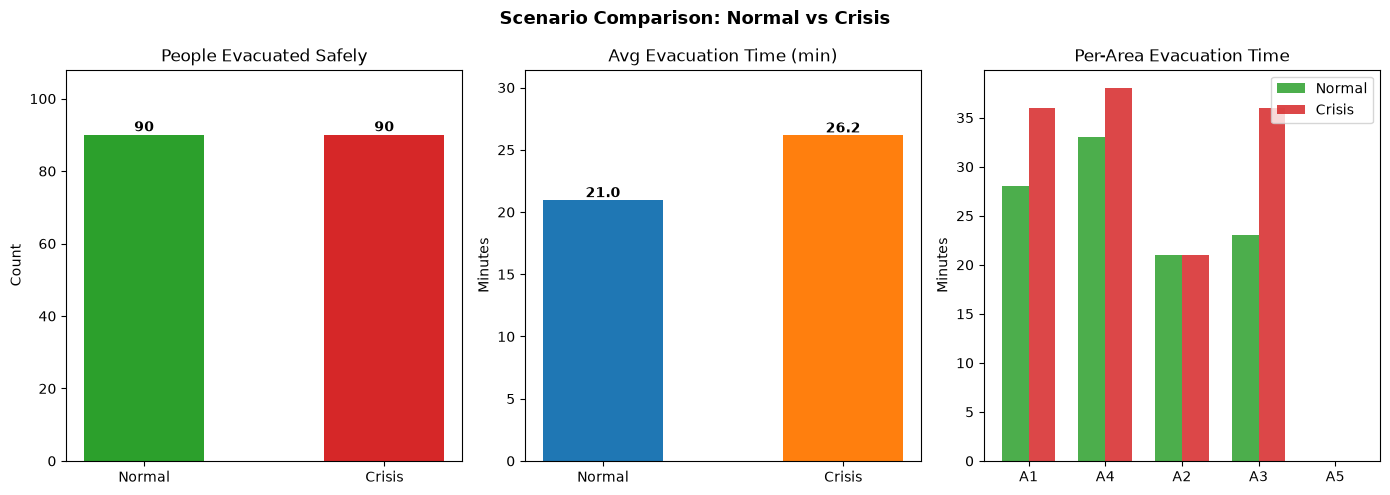

In [16]:
# ── Comparative Visualisation ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle("Scenario Comparison: Normal vs Crisis", fontsize=13, fontweight="bold")

sc_labels = [scenario_normal["scenario"].split()[0],
             "Crisis"]

# ── 1. People evacuated ──
ax = axes[0]
vals = [scenario_normal["people_saved"], scenario_crisis["people_saved"]]
bars = ax.bar(sc_labels, vals, color=["#2ca02c", "#d62728"], width=0.5)
ax.set_title("People Evacuated Safely")
ax.set_ylabel("Count")
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 1, str(v), ha="center", fontweight="bold")
ax.set_ylim(0, max(vals) * 1.2)

# ── 2. Average evacuation time ──
ax = axes[1]
vals = [scenario_normal["avg_time_min"], scenario_crisis["avg_time_min"]]
bars = ax.bar(sc_labels, vals, color=["#1f77b4", "#ff7f0e"], width=0.5)
ax.set_title("Avg Evacuation Time (min)")
ax.set_ylabel("Minutes")
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.2, f"{v}", ha="center", fontweight="bold")
ax.set_ylim(0, max(vals) * 1.2)

# ── 3. Per-area time comparison ──
ax = axes[2]
area_ids = [d["area"] for d in scenario_normal["detail"]]
times_n  = [d["time"] for d in scenario_normal["detail"]]
times_c  = [d["time"] for d in scenario_crisis["detail"]]
x        = np.arange(len(area_ids))
w        = 0.35
ax.bar(x - w/2, times_n, w, label="Normal", color="#2ca02c", alpha=0.85)
ax.bar(x + w/2, times_c, w, label="Crisis",  color="#d62728", alpha=0.85)
ax.set_title("Per-Area Evacuation Time")
ax.set_ylabel("Minutes")
ax.set_xticks(x)
ax.set_xticklabels(area_ids)
ax.legend()

plt.tight_layout()
plt.show()


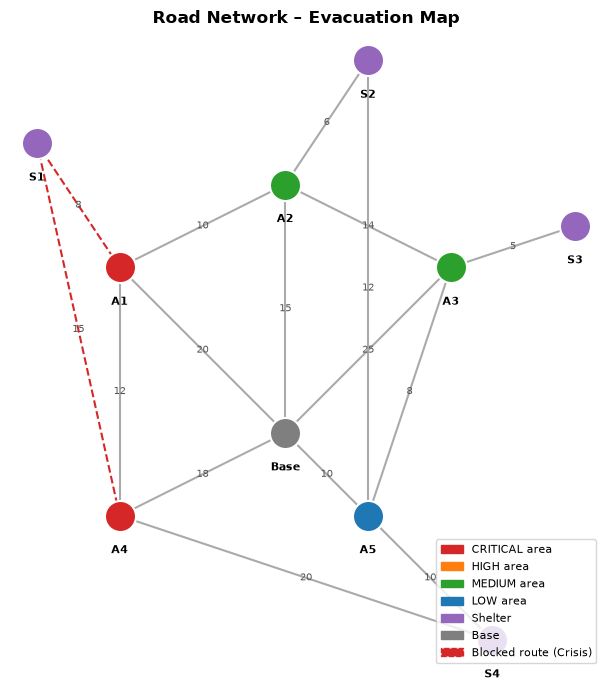


Simulation complete. Crisis scenario adapted by rerouting through alternate shelters.


In [17]:
# ── Road Network Visualisation ────────────────────────────────────────────────
import matplotlib.patheffects as pe

pos = {
    "Base": (0, 0),
    "A1":   (-2,  2), "A2":  (0,  3), "A3": (2,  2),
    "A4":   (-2, -1), "A5":  (1, -1),
    "S1":   (-3,  3.5), "S2": (1,  4.5), "S3": (3.5, 2.5), "S4": (2.5, -2.5),
}
node_colors = {
    "Base": "#7f7f7f",
    **{k: ("#d62728" if affected_areas[k]["priority"] == "CRITICAL" else
           "#ff7f0e" if affected_areas[k]["priority"] == "HIGH" else
           "#2ca02c" if affected_areas[k]["priority"] == "MEDIUM" else "#1f77b4")
       for k in affected_areas},
    **{s: "#9467bd" for s in shelters},
}

fig, ax = plt.subplots(figsize=(10, 7))
ax.set_title("Road Network – Evacuation Map", fontsize=12, fontweight="bold")
blocked = {("A1","S1"), ("S1","A1"), ("A4","S1"), ("S1","A4")}

for u, neighbours in road_network.items():
    for v, w in neighbours.items():
        if u < v:
            xu, yu = pos[u]; xv, yv = pos[v]
            is_blocked = (u, v) in blocked or (v, u) in blocked
            color = "#d62728" if is_blocked else "#aaaaaa"
            ls    = "--"     if is_blocked else "-"
            ax.plot([xu, xv], [yu, yv], color=color, linewidth=1.5, linestyle=ls, zorder=1)
            mx, my = (xu+xv)/2, (yu+yv)/2
            ax.text(mx, my, str(w), fontsize=7, ha="center", va="center",
                    color="#555555", zorder=2)

for node, (x, y) in pos.items():
    c = node_colors.get(node, "#aec7e8")
    ax.scatter(x, y, s=500, c=c, zorder=3, edgecolors="white", linewidths=1.5)
    ax.text(x, y-0.35, node, fontsize=8, ha="center", va="top", fontweight="bold")

legend_patches = [
    mpatches.Patch(color="#d62728", label="CRITICAL area"),
    mpatches.Patch(color="#ff7f0e", label="HIGH area"),
    mpatches.Patch(color="#2ca02c", label="MEDIUM area"),
    mpatches.Patch(color="#1f77b4", label="LOW area"),
    mpatches.Patch(color="#9467bd", label="Shelter"),
    mpatches.Patch(color="#7f7f7f", label="Base"),
    mpatches.Patch(color="#d62728", linestyle="--", label="Blocked route (Crisis)"),
]
ax.legend(handles=legend_patches, loc="lower right", fontsize=8)
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()
print("\nSimulation complete. Crisis scenario adapted by rerouting through alternate shelters.")
